# spread_source 02 — Smoke plume and source localisation
**Question.** Gas boxes read some smoke "depth". Where is the fire?
**Idea.** Predict what each box *would* read for every possible source cell (a physical plume model), then weigh the cells by how well they explain *all* readings, including the boxes that read nothing.

## 1. The plume model
Steady Gaussian plume from a ground-level point source, Briggs rural neutral dispersion (class D):
`σy = 0.08 x (1+0.0001x)^-1/2`, `σz = 0.06 x (1+0.0015x)^-1/2`,
`C = Q / (2π u σy σz) · exp(-y²/2σy²) · [exp(-(z-H)²/2σz²) + exp(-(z+H)²/2σz²)]`. Unit-free (Q is unknown anyway).
Check of the maths: the total flux through any vertical plane must equal Q.

In [1]:
import sys, pathlib, math
import numpy as np
import matplotlib.pyplot as plt
ROOT = pathlib.Path.cwd().resolve().parents[1]
sys.path[:0] = [str(ROOT / "python/src"), str(ROOT.parent / "common/python/src")]
from spread_source import concentration, SourceLocator, receptor_unit_response, sigma_yz, experiments as X
u = 4.0
ys = np.linspace(-1500, 1500, 3001); zs = np.linspace(0, 1500, 3001); Y, Z = np.meshgrid(ys, zs)
for x in (1000, 2000, 4000):
    flux = np.trapezoid(np.trapezoid(concentration(x, Y, Z, u) * u, ys, axis=1), zs)
    print(f"x = {x} m: integrated flux / Q = {flux:.4f}   (criterion 1 ± 0.02)")

x = 1000 m: integrated flux / Q = 1.0000   (criterion 1 ± 0.02)


x = 2000 m: integrated flux / Q = 1.0000   (criterion 1 ± 0.02)


x = 4000 m: integrated flux / Q = 1.0000   (criterion 1 ± 0.02)


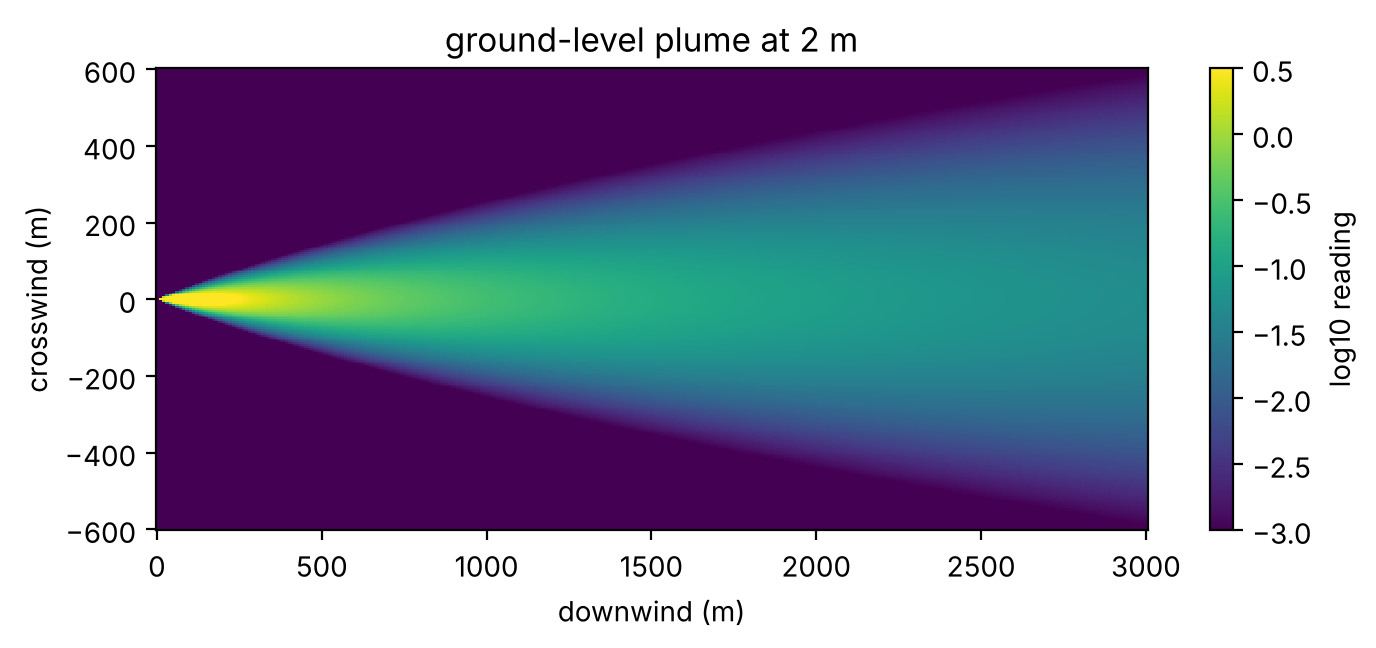

plume 1σy half-width at 1 km: 76 m, at 3 km: 210 m


In [2]:
xx, yy = np.meshgrid(np.linspace(1, 3000, 300), np.linspace(-600, 600, 241))
c = concentration(xx, yy, 2.0, u)
plt.figure(figsize=(8, 3)); plt.pcolormesh(xx, yy, np.log10(c * 1e4 + 1e-6), shading="auto", vmin=-3, vmax=0.5); plt.colorbar(label="log10 reading"); plt.xlabel("downwind (m)"); plt.ylabel("crosswind (m)"); plt.title("ground-level plume at 2 m"); plt.show()
print("plume 1σy half-width at 1 km: %.0f m, at 3 km: %.0f m" % (sigma_yz(1000)[0], sigma_yz(3000)[0]))

**Reading.** The plume is narrow: at 1 km only ±76 m (1σ) are covered. A box must be almost exactly downwind to read anything.

## 2. The inversion
For each candidate source cell `s` and each detecting box `i`: `log reading_i = log Q + log c_i(s) + ε_i`, `ε ~ N(0, 0.3²)` (30 % noise). `Q` is unknown, so it is *profiled out* (set to its best value for each cell).
A box that reads **below the detection limit** is evidence too: a cell that would put that box in the middle of the plume is unlikely. Prior: uniform. Posterior = normalised likelihood on a 50 m grid.

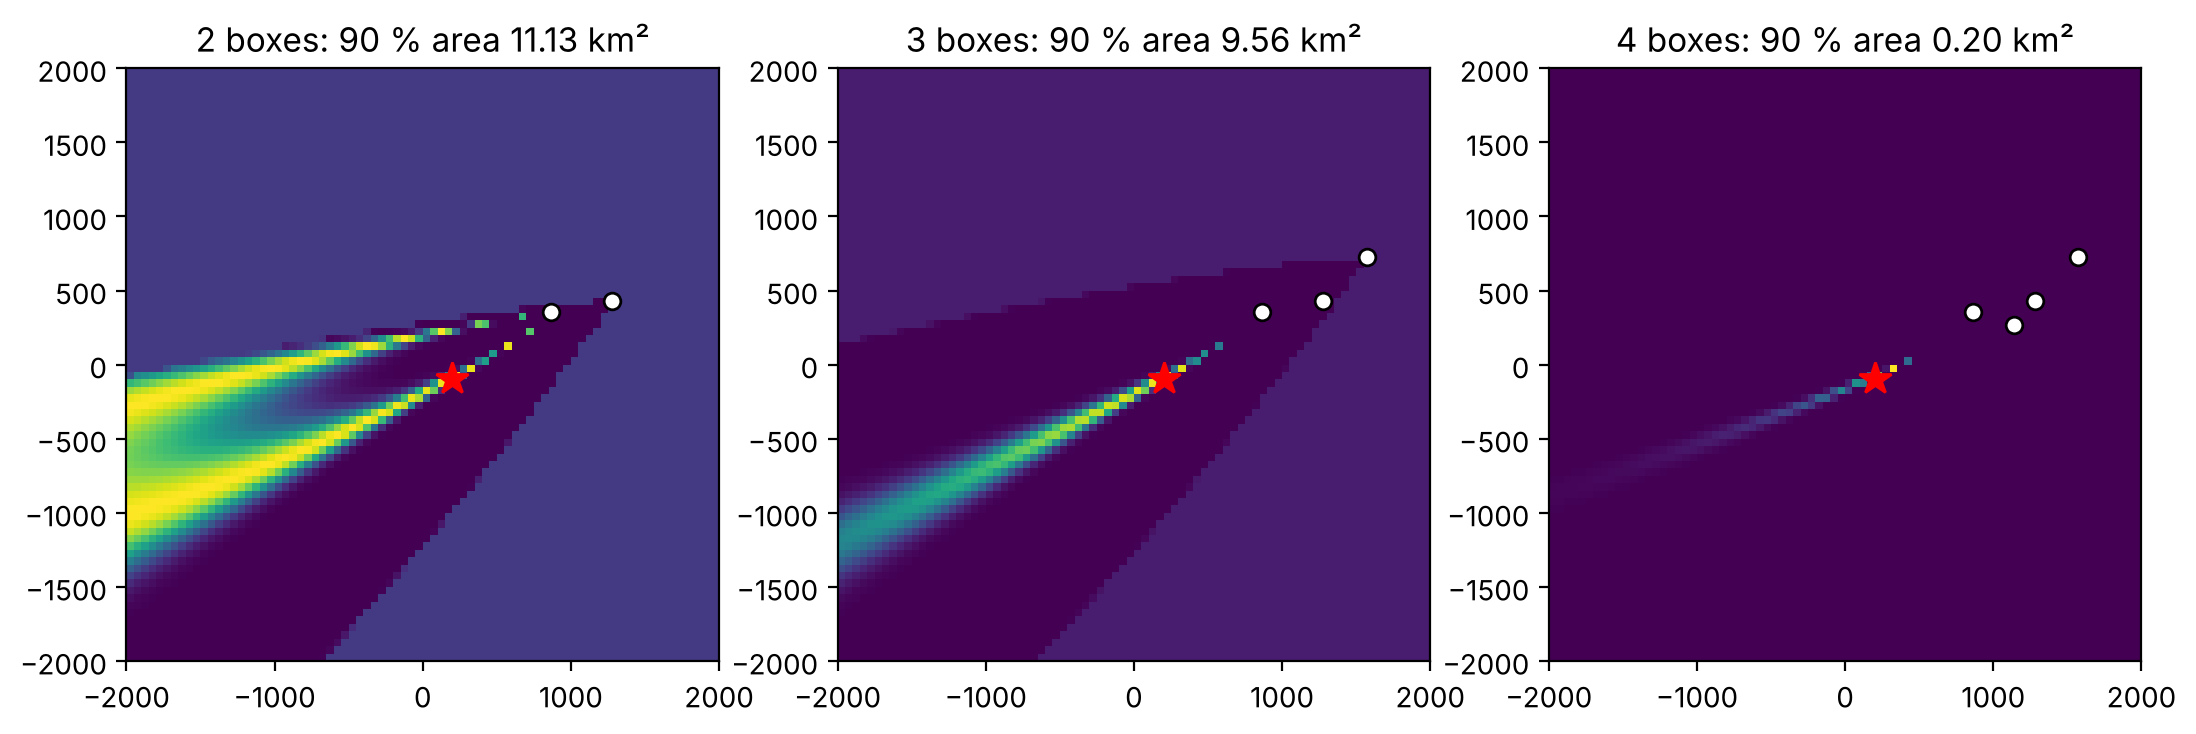

In [3]:
rng = np.random.default_rng(2)
src = (200.0, -100.0); wd, u = 60.0, 5.0
th = math.radians(90 - wd)
frame = lambda xd, yc: (src[0] + xd * math.cos(th) - yc * math.sin(th), src[1] + xd * math.sin(th) + yc * math.cos(th))
boxes = [frame(800, 60), frame(1200, -80), frame(1600, 30), frame(1000, -150)]
depth = [receptor_unit_response(src, b, wd, u) * 1e4 * math.exp(rng.normal(0, 0.3)) for b in boxes]
loc = SourceLocator((-2000, 2000, -2000, 2000), cell=50.0)
fig, ax = plt.subplots(1, 3, figsize=(13, 4))
for a, k in zip(ax, (2, 3, 4)):
    post = loc.posterior(boxes[:k], depth[:k], wd, u); s = loc.summarize(post, boxes[:k])
    a.pcolormesh(loc.gx, loc.gy, post, shading="auto"); a.plot(*src, "r*", ms=12); a.plot(*zip(*boxes[:k]), "wo", mec="k")
    a.set_title(f"{k} boxes: 90 % area {s['area90_m2']/1e6:.2f} km²"); a.set_aspect("equal")
plt.show()

**Reading.** With 2 boxes the answer is a *curve* along the wind axis (3 unknowns — x, y, Q — and only 2 readings): the credible area is large and the output says so. The area collapses to a small blob only from 4 boxes (3 boxes are in between, see section 3).

## 3. How often does it work? 200 trials per row, noise σ = 0.3
Two geometries, because they answer different questions:
- **random**: boxes anywhere in a 4 × 4 km domain, wind in any direction. The narrow plume usually misses all boxes → no alarm, or only one box alarms (cannot localise).
- **in plume** (favourable, best case): boxes 0.5–3 km downwind, crosswind offset within ~1σ.
Success = estimated source within 500 m.

In [4]:
print("RANDOM geometry (conditional on at least 2 boxes alarming):")
for nb in (2, 3, 4, 6, 10):
    tr = X.run(nb, 200, seed=1)
    a1, a2 = X.summarize(tr, 1), X.summarize(tr, 2)
    print(f"  {nb:2d} boxes | alarm in >=1 box: {a1.get('frac_alarm', 0):.2f} | >=2 boxes: {a2.get('frac_alarm', 0):.2f} | success if >=2 alarm: {a2.get('success', float('nan')):.2f} (n={a2.get('n')})")
print("\nIN-PLUME geometry (all boxes alarming):")
for nb in (2, 3, 4, 6):
    s = X.summarize(X.run(nb, 200, seed=1, mode="in_plume"), min_det=nb)
    print(f"  {nb} boxes | success {s['success']:.2f} | median error {s['median_err']:.0f} m | median 90 % area {s['median_area90_km2']:.2f} km²")

RANDOM geometry (conditional on at least 2 boxes alarming):
   2 boxes | alarm in >=1 box: 0.14 | >=2 boxes: 0.01 | success if >=2 alarm: 0.00 (n=2)
   3 boxes | alarm in >=1 box: 0.19 | >=2 boxes: 0.01 | success if >=2 alarm: 0.33 (n=3)


   4 boxes | alarm in >=1 box: 0.26 | >=2 boxes: 0.01 | success if >=2 alarm: 1.00 (n=2)


   6 boxes | alarm in >=1 box: 0.41 | >=2 boxes: 0.09 | success if >=2 alarm: 0.24 (n=17)


  10 boxes | alarm in >=1 box: 0.56 | >=2 boxes: 0.17 | success if >=2 alarm: 0.71 (n=34)

IN-PLUME geometry (all boxes alarming):


  2 boxes | success 0.39 | median error 767 m | median 90 % area 45.78 km²


  3 boxes | success 0.65 | median error 338 m | median 90 % area 40.84 km²


  4 boxes | success 0.71 | median error 276 m | median 90 % area 0.72 km²


  6 boxes | success 0.89 | median error 151 m | median 90 % area 0.10 km²


## 4. Conclusions
- The maths is right (flux test) and the inversion works when several boxes sit in the plume; the 90 % area **shrinks as boxes are added** (2 → 3 → 4 → 6).
- The pre-registered criterion "≥ 70 % within 500 m with 4 boxes" is met **only in the favourable geometry (0.71)**; with randomly placed boxes it is not met, because a narrow steady plume rarely covers ≥ 2 boxes.
- Real smoke is wider and meanders; our steady narrow plume is probably pessimistic about *detection* and optimistic about *shape*. Neither was measured. Consequence for the project: the **bearing from a single alarming box** (wind direction) is the honest output for 1 box; a map only from ≥ 3 simultaneous alarms.